# Automated Data Quality Validation for Large-Scale AIS Vessel Telemetry

Case study for the CITE expanded abstract (Big Data track).

**Data source:** NOAA / BOEM MarineCadastre - Nationwide AIS 2023 (1-minute sampled, daily CSV files).

**Why 2023 and not 2025:** the 2025 files are already pre-cleaned (sentinels replaced by nulls, invalid MMSI removed).
The 2023 files keep the raw AIS conventions, so the quality issues are still measurable.

**Pipeline:** download (zip) -> CSV -> Parquet -> DuckDB -> record-level rules -> trajectory-level rules -> summary table and charts.

| Rule | Dimension (Wang; Strong, 1996) | Check |
|---|---|---|
| R1 | Validity | Coordinates out of range / sentinel (91, 181) / null island (0, 0) |
| R2 | Validity | Malformed or non-vessel MMSI |
| R3-R7 | Completeness / Validity | SOG, COG and Heading not available or out of range |
| R8 | Uniqueness | Duplicated (MMSI, timestamp) |
| R9 | Timeliness | Timestamp outside the source file day |
| R10 | Completeness | Transmission gaps between consecutive points |
| R11 | Plausibility | Implied speed between consecutive points is physically impossible |

## 0. Setup
Run once. In VS Code, select the kernel of the virtual environment where the packages are installed.

In [1]:
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import time
import zipfile
import tempfile
from datetime import date, datetime, timedelta
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from tqdm.auto import tqdm

# --- Sample definition -------------------------------------------------------
# 1 day   -> develop and test the notebook
# 7 days  -> expanded abstract (one full week, Mon-Sun)
# 28 days -> extended version of the paper
YEAR = 2023
START = date(2023, 3, 6)  # Monday
N_DAYS = 7

# --- Rule thresholds ---------------------------------------------------------
GAP_MIN = 30        # transmission gap threshold (minutes)
MAX_SPEED_KN = 50   # implied speed considered physically implausible (knots)

BASE_URL = f'https://coast.noaa.gov/htdata/CMSP/AISDataHandler/{YEAR}'
DATA_DIR = Path('data')
ZIP_DIR = DATA_DIR / 'zip'
PARQUET_DIR = DATA_DIR / 'parquet'
OUT_DIR = Path('output')
for d in (ZIP_DIR, PARQUET_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

DAYS = [START + timedelta(days=i) for i in range(N_DAYS)]
DAYS

## 1. Download
Files already downloaded are skipped. If a download fails with 404, open
`https://coast.noaa.gov/htdata/CMSP/AISDataHandler/2023/index.html` and check the file name pattern.

In [3]:
def download(day):
    name = f'AIS_{day:%Y_%m_%d}.zip'
    target = ZIP_DIR / name
    if target.exists():
        return target
    tmp = target.with_suffix('.part')
    with requests.get(f'{BASE_URL}/{name}', stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get('content-length', 0))
        with open(tmp, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True, desc=name) as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    tmp.rename(target)
    return target

zips = [download(d) for d in DAYS]
zips

AIS_2023_03_06.zip: 100%|██████████| 326M/326M [03:08<00:00, 1.73MB/s] 


[PosixPath('data/zip/AIS_2023_03_06.zip')]

### 1.1 Inspect the raw header
Check that the column names match `AIS_TYPES` below before converting.

In [4]:
with zipfile.ZipFile(zips[0]) as z:
    csv_name = next(n for n in z.namelist() if n.lower().endswith('.csv'))
    print(csv_name, f'- {z.getinfo(csv_name).file_size / 1e6:.0f} MB uncompressed')
    with z.open(csv_name) as f:
        for _ in range(4):
            print(f.readline().decode().rstrip())

AIS_2023_03_06.csv - 892 MB uncompressed
MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass
367162940,2023-03-06T00:00:04,29.76426,-95.10884,0.0,178.1,266.0,SAN JACINTO,,WDD5743,31,0,16,7,,52,A
368084470,2023-03-06T00:00:03,30.06955,-90.89518,0.0,251.7,321.0,LAILA ADELE,,WDK7438,57,12,24,9,3.0,57,A
368047380,2023-03-06T00:00:02,37.77648,-87.10677,0.0,216.2,90.0,BETTY R YAGER,,WDK3660,31,15,31,9,2.7,31,A


## 2. CSV -> Parquet
Each daily CSV is extracted to a temporary folder, typed, tagged with its source day (`file_date`) and written as Parquet (zstd).

In [5]:
con = duckdb.connect(str(DATA_DIR / 'ais.duckdb'))

# Identifiers stay as text so malformed values can be detected later
AIS_TYPES = {
    'MMSI': 'VARCHAR', 'BaseDateTime': 'TIMESTAMP', 'LAT': 'DOUBLE', 'LON': 'DOUBLE',
    'SOG': 'DOUBLE', 'COG': 'DOUBLE', 'Heading': 'DOUBLE', 'VesselName': 'VARCHAR',
    'IMO': 'VARCHAR', 'CallSign': 'VARCHAR',
}
TYPES_SQL = '{' + ', '.join(f"'{k}': '{v}'" for k, v in AIS_TYPES.items()) + '}'


def to_parquet(zip_path):
    out = PARQUET_DIR / f'{zip_path.stem}.parquet'
    if out.exists():
        return out
    file_day = datetime.strptime(zip_path.stem, 'AIS_%Y_%m_%d').date()
    with zipfile.ZipFile(zip_path) as z, tempfile.TemporaryDirectory() as tmp:
        csv_name = next(n for n in z.namelist() if n.lower().endswith('.csv'))
        csv_path = Path(z.extract(csv_name, tmp)).as_posix()
        con.execute(f'''
            COPY (
                SELECT *, DATE '{file_day}' AS file_date
                FROM read_csv('{csv_path}', header = true, types = {TYPES_SQL})
            ) TO '{out.as_posix()}' (FORMAT parquet, COMPRESSION zstd)
        ''')
    return out


t0 = time.perf_counter()
parquets = [to_parquet(z) for z in tqdm(zips, desc='CSV -> Parquet')]
print(f'Conversion time: {time.perf_counter() - t0:.1f} s')

sizes = pd.DataFrame({
    'file': [p.stem for p in parquets],
    'zip_mb': [(ZIP_DIR / f'{p.stem}.zip').stat().st_size / 1e6 for p in parquets],
    'parquet_mb': [p.stat().st_size / 1e6 for p in parquets],
}).round(1)
sizes

CSV -> Parquet: 100%|██████████| 1/1 [00:02<00:00,  2.64s/it]

Conversion time: 2.6 s


,file,zip_mb,parquet_mb
0,AIS_2023_03_06,326.1,209.0


## 3. Dataset overview
These numbers go into **Materials and Methods** (sample size, vessels, period).

In [6]:
files_sql = '[' + ', '.join(f"'{p.as_posix()}'" for p in parquets) + ']'
con.execute(f'CREATE OR REPLACE VIEW ais AS SELECT * FROM read_parquet({files_sql})')

TOTAL = con.sql('SELECT COUNT(*) FROM ais').fetchone()[0]
overview = con.sql('''
    SELECT COUNT(*)             AS records,
           COUNT(DISTINCT MMSI) AS vessels,
           MIN(BaseDateTime)    AS first_ts,
           MAX(BaseDateTime)    AS last_ts
    FROM ais
''').df()
overview

,records,vessels,first_ts,last_ts
0,8312851,16563,2023-03-06,2023-03-06 23:59:59


In [7]:
# Column profile: min, max, null %, approx. distinct values
con.sql('SUMMARIZE ais').df()

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,MMSI,VARCHAR,1,998975541,17006,None,None,None,None,None,8312851,0.00
1,BaseDateTime,TIMESTAMP,2023-03-06 00:00:00,2023-03-06 23:59:59,98894,2023-03-06 12:12:45.523857,None,2023-03-06 06:16:47.051485,2023-03-06 12:21:53.602054,2023-03-06 18:17:16.067438,8312851,0.00
2,LAT,DOUBLE,0.04071,49.83498,1215443,34.21412794275633,7.4362408298771205,29.437236245921714,31.356985910577386,39.344446661940935,8312851,0.00
3,LON,DOUBLE,-160.26549,145.25759,1500299,-93.60839977599893,19.164767711842973,-96.17429868997002,-90.22096798475972,-80.57270800308389,8312851,0.00
4,SOG,DOUBLE,0.0,102.3,581,2.2552893706393853,6.586205698180011,0.0,0.0,1.5603719622833365,8312851,0.00
5,COG,DOUBLE,0.0,409.4,3724,214.4622809791655,114.36230254451856,119.50996912629078,233.7336767311696,316.40100694788373,8312851,0.00
6,Heading,DOUBLE,0.0,511.0,378,352.97082805886936,180.0522470865653,189.74277822005428,510.95469979428265,511.0,8312851,0.00
7,VesselName,VARCHAR,############,ZYANA K,11279,None,None,None,None,None,8312851,0.23
8,IMO,VARCHAR,IMO0000000,IMO999999999,3928,None,None,None,None,None,8312851,49.13
9,CallSign,VARCHAR,-------,ZZZZZ,12879,None,None,None,None,None,8312851,12.08


## 4. Record-level rules (R1-R9)
Each rule returns the number of affected records. AIS "not available" sentinels follow ITU-R M.1371:
latitude 91, longitude 181, SOG 102.3, COG 360, heading 511.

In [8]:
RECORD_RULES = [
    ('R1', 'Validity', 'Coordinates out of range, sentinel (91/181) or null island (0,0)', '''
        SELECT COUNT(*) FROM ais
        WHERE LAT IS NULL OR LON IS NULL
           OR LAT NOT BETWEEN -90 AND 90 OR LON NOT BETWEEN -180 AND 180
           OR (LAT = 0 AND LON = 0)'''),
    ('R2', 'Validity', 'MMSI is not a 9-digit vessel identifier (first digit 2-7)', '''
        SELECT COUNT(*) FROM ais
        WHERE MMSI IS NULL OR NOT regexp_full_match(MMSI, '[2-7][0-9]{8}')'''),
    ('R3', 'Completeness', 'SOG not available (102.3) or null', '''
        SELECT COUNT(*) FROM ais WHERE SOG IS NULL OR SOG = 102.3'''),
    ('R4', 'Validity', 'SOG out of range (< 0 or > 102.3 kn)', '''
        SELECT COUNT(*) FROM ais WHERE SOG < 0 OR SOG > 102.3'''),
    ('R5', 'Completeness', 'COG not available (360) or null', '''
        SELECT COUNT(*) FROM ais WHERE COG IS NULL OR COG = 360'''),
    ('R6', 'Validity', 'COG out of range (< 0 or > 360)', '''
        SELECT COUNT(*) FROM ais WHERE COG < 0 OR COG > 360'''),
    ('R7', 'Completeness', 'Heading not available (511) or null', '''
        SELECT COUNT(*) FROM ais WHERE Heading IS NULL OR Heading = 511'''),
    ('R8', 'Uniqueness', 'Extra records for the same (MMSI, timestamp)', '''
        SELECT COALESCE(SUM(n - 1), 0) FROM (
            SELECT COUNT(*) AS n FROM ais
            GROUP BY MMSI, BaseDateTime
            HAVING COUNT(*) > 1
        )'''),
    ('R9', 'Timeliness', 'Timestamp null or outside the day of its source file', '''
        SELECT COUNT(*) FROM ais
        WHERE BaseDateTime IS NULL OR CAST(BaseDateTime AS DATE) <> file_date'''),
]

results = []  # re-running this cell resets the results


def run_rule(rule_id, dimension, description, sql, denominator, unit, params=None):
    t0 = time.perf_counter()
    cur = con.execute(sql, params) if params else con.execute(sql)
    affected = cur.fetchone()[0]
    results.append({
        'rule': rule_id,
        'dimension': dimension,
        'description': description,
        'affected': affected,
        'denominator': denominator,
        'unit': unit,
        'pct': 100 * affected / denominator if denominator else None,
        'runtime_s': round(time.perf_counter() - t0, 2),
    })


for rule in RECORD_RULES:
    run_rule(*rule, denominator=TOTAL, unit='records')

pd.DataFrame(results)

,rule,dimension,description,affected,denominator,unit,pct,runtime_s
0,R1,Validity,"Coordinates out of range, sentinel (91/181) or...",0,8312851,records,0.000000,0.00
1,R2,Validity,MMSI is not a 9-digit vessel identifier (first...,12420,8312851,records,0.149407,0.03
2,R3,Completeness,SOG not available (102.3) or null,21551,8312851,records,0.259249,0.02
3,R4,Validity,SOG out of range (< 0 or > 102.3 kn),0,8312851,records,0.000000,0.00
4,R5,Completeness,COG not available (360) or null,1238371,8312851,records,14.897067,0.02
5,R6,Validity,COG out of range (< 0 or > 360),2,8312851,records,0.000024,0.01
6,R7,Completeness,Heading not available (511) or null,4312302,8312851,records,51.875127,0.02
7,R8,Uniqueness,"Extra records for the same (MMSI, timestamp)",218,8312851,records,0.002622,0.07
8,R9,Timeliness,Timestamp null or outside the day of its sourc...,0,8312851,records,0.000000,0.01


### 4.1 Completeness of static (vessel identity) fields
Measured per vessel, since these fields describe the vessel and not each position report.

In [9]:
con.sql('''
    WITH vessels AS (
        SELECT MMSI,
               MAX(NULLIF(TRIM(VesselName), '')) AS vessel_name,
               MAX(NULLIF(TRIM(IMO), ''))        AS imo,
               MAX(NULLIF(TRIM(CallSign), ''))   AS call_sign,
               MAX(VesselType)                   AS vessel_type,
               MAX(Length)                       AS length
        FROM ais
        GROUP BY MMSI
    )
    SELECT COUNT(*) AS vessels,
           ROUND(100 * AVG((vessel_name IS NULL)::INT), 2) AS name_missing_pct,
           ROUND(100 * AVG((imo IS NULL)::INT), 2)         AS imo_missing_pct,
           ROUND(100 * AVG((call_sign IS NULL)::INT), 2)   AS callsign_missing_pct,
           ROUND(100 * AVG((vessel_type IS NULL)::INT), 2) AS type_missing_pct,
           ROUND(100 * AVG((length IS NULL)::INT), 2)      AS length_missing_pct
    FROM vessels
''').df()

,vessels,name_missing_pct,imo_missing_pct,callsign_missing_pct,type_missing_pct,length_missing_pct
0,16563,0.68,40.22,22.95,0.5,7.37


## 5. Trajectory-level rules (R10-R11)
Built on a clean point set (valid MMSI and coordinates, one record per MMSI and timestamp).
Each segment links a point to the previous point of the same vessel; distance uses the haversine formula
with Earth radius = 3440.065 nautical miles, so implied speed comes out in knots.

In [10]:
t0 = time.perf_counter()
con.execute('''
    CREATE OR REPLACE TABLE pts AS
    SELECT MMSI, BaseDateTime AS ts, LAT, LON, SOG
    FROM ais
    WHERE regexp_full_match(MMSI, '[2-7][0-9]{8}')
      AND BaseDateTime IS NOT NULL
      AND LAT BETWEEN -90 AND 90 AND LON BETWEEN -180 AND 180
      AND NOT (LAT = 0 AND LON = 0)
    QUALIFY ROW_NUMBER() OVER (PARTITION BY MMSI, BaseDateTime ORDER BY SOG) = 1
''')

con.execute('''
    CREATE OR REPLACE TABLE seg AS
    WITH s AS (
        SELECT MMSI, ts, LAT, LON,
               LAG(ts)  OVER w AS prev_ts,
               LAG(LAT) OVER w AS prev_lat,
               LAG(LON) OVER w AS prev_lon
        FROM pts
        WINDOW w AS (PARTITION BY MMSI ORDER BY ts)
    )
    SELECT MMSI, prev_ts, ts,
           date_diff('second', prev_ts, ts) AS dt_s,
           2 * 3440.065 * asin(least(1, sqrt(
               pow(sin(radians(LAT - prev_lat) / 2), 2)
               + cos(radians(prev_lat)) * cos(radians(LAT))
                 * pow(sin(radians(LON - prev_lon) / 2), 2)
           ))) AS dist_nm
    FROM s
    WHERE prev_ts IS NOT NULL
''')
print(f'pts + seg build time: {time.perf_counter() - t0:.1f} s')

SEG_TOTAL = con.sql('SELECT COUNT(*) FROM seg').fetchone()[0]

run_rule('R10', 'Completeness', f'Gap between consecutive reports > {GAP_MIN} min', '''
    SELECT COUNT(*) FROM seg WHERE dt_s > $gap_s''',
    denominator=SEG_TOTAL, unit='segments', params={'gap_s': GAP_MIN * 60})

run_rule('R11', 'Plausibility', f'Implied speed between consecutive reports > {MAX_SPEED_KN} kn', '''
    SELECT COUNT(*) FROM seg WHERE dist_nm / (dt_s / 3600.0) > $max_kn''',
    denominator=SEG_TOTAL, unit='segments', params={'max_kn': MAX_SPEED_KN})

pd.DataFrame(results).tail(2)

pts + seg build time: 0.9 s


,rule,dimension,description,affected,denominator,unit,pct,runtime_s
9,R10,Completeness,Gap between consecutive reports > 30 min,15874,8283716,segments,0.191629,0.00
10,R11,Plausibility,Implied speed between consecutive reports > 50 kn,3480,8283716,segments,0.042010,0.01


### 5.1 Sensitivity analysis
Shows how R10 and R11 change with the threshold. Useful to justify the chosen values in the paper.

In [11]:
gap_sens = con.sql('''
    SELECT t.gap_min,
           COUNT(*) FILTER (WHERE s.dt_s > t.gap_min * 60) AS segments,
           ROUND(100.0 * COUNT(*) FILTER (WHERE s.dt_s > t.gap_min * 60) / COUNT(*), 3) AS pct
    FROM seg s, (SELECT UNNEST([10, 30, 60, 360, 1440]) AS gap_min) t
    GROUP BY t.gap_min ORDER BY t.gap_min
''').df()

speed_sens = con.sql('''
    SELECT t.max_kn,
           COUNT(*) FILTER (WHERE s.dist_nm / (s.dt_s / 3600.0) > t.max_kn) AS segments,
           ROUND(100.0 * COUNT(*) FILTER (WHERE s.dist_nm / (s.dt_s / 3600.0) > t.max_kn) / COUNT(*), 4) AS pct
    FROM seg s, (SELECT UNNEST([30, 50, 80, 120]) AS max_kn) t
    GROUP BY t.max_kn ORDER BY t.max_kn
''').df()

display(gap_sens, speed_sens)

,gap_min,segments,pct
0,10,91629,1.106
1,30,15874,0.192
2,60,6813,0.082
3,360,1002,0.012
4,1440,0,0.000


,max_kn,segments,pct
0,30,11302,0.1364
1,50,3480,0.0420
2,80,3103,0.0375
3,120,2947,0.0356


## 6. Results table
Saved as CSV and printed as Markdown, ready to adapt into Table 1 of the paper.

In [12]:
summary = pd.DataFrame(results)
summary['pct'] = summary['pct'].round(4)
summary.to_csv(OUT_DIR / 'dq_results.csv', index=False)

print(summary[['rule', 'dimension', 'description', 'affected', 'unit', 'pct', 'runtime_s']]
      .to_markdown(index=False))

| rule   | dimension    | description                                                      |   affected | unit     |     pct |   runtime_s |
|:-------|:-------------|:-----------------------------------------------------------------|-----------:|:---------|--------:|------------:|
| R1     | Validity     | Coordinates out of range, sentinel (91/181) or null island (0,0) |          0 | records  |  0      |        0    |
| R2     | Validity     | MMSI is not a 9-digit vessel identifier (first digit 2-7)        |      12420 | records  |  0.1494 |        0.03 |
| R3     | Completeness | SOG not available (102.3) or null                                |      21551 | records  |  0.2592 |        0.02 |
| R4     | Validity     | SOG out of range (< 0 or > 102.3 kn)                             |          0 | records  |  0      |        0    |
| R5     | Completeness | COG not available (360) or null                                  |    1238371 | records  | 14.8971 |        0.02 |
| R6     | Va

## 7. Figures (300 dpi, for the paper)

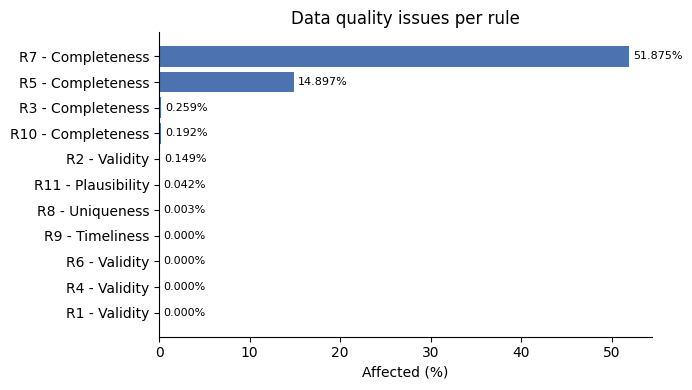

In [13]:
# Figure 1 - share of affected records/segments per rule
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = summary.sort_values('pct')
bars = ax.barh(plot_df['rule'] + ' - ' + plot_df['dimension'], plot_df['pct'], color='#4C72B0')
ax.bar_label(bars, labels=[f'{v:.3f}%' for v in plot_df['pct']], padding=3, fontsize=8)
ax.set_xlabel('Affected (%)')
ax.set_title('Data quality issues per rule')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / 'fig1_rules.png', dpi=300)
plt.show()

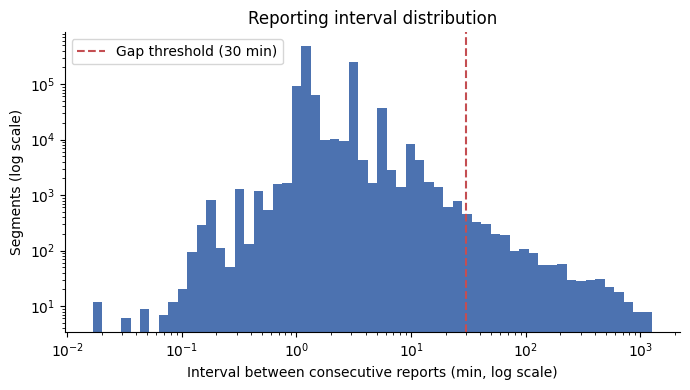

In [16]:
# Figure 2 - distribution of the interval between consecutive reports (sampled)
dt = con.sql('SELECT dt_s / 60.0 AS dt_min FROM seg USING SAMPLE 1000000 ROWS').df()['dt_min']
dt = dt[dt > 0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(dt, bins=np.logspace(np.log10(dt.min()), np.log10(dt.max()), 60), color='#4C72B0')
ax.axvline(GAP_MIN, color='#C44E52', linestyle='--', label=f'Gap threshold ({GAP_MIN} min)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Interval between consecutive reports (min, log scale)')
ax.set_ylabel('Segments (log scale)')
ax.set_title('Reporting interval distribution')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / 'fig2_gaps.png', dpi=300)
plt.show()

## 8. Numbers for the text
Copy these into **Materials and Methods** and **Results**.

In [15]:
print(f'Period:              {DAYS[0]} to {DAYS[-1]} ({len(DAYS)} days)')
print(f'Records:             {TOTAL:,}')
print(f'Vessels (MMSI):      {overview.loc[0, "vessels"]:,}')
print(f'Segments:            {SEG_TOTAL:,}')
print(f'Zip size:            {sizes["zip_mb"].sum():,.0f} MB')
print(f'Parquet size:        {sizes["parquet_mb"].sum():,.0f} MB')
print(f'Total rule runtime:  {summary["runtime_s"].sum():.1f} s')
print(f'DuckDB version:      {duckdb.__version__}')

Period:              2023-03-06 to 2023-03-06 (1 days)
Records:             8,312,851
Vessels (MMSI):      16,563
Segments:            8,283,716
Zip size:            326 MB
Parquet size:        209 MB
Total rule runtime:  0.2 s
DuckDB version:      1.4.5
